# **Visión por Computadora 1 - Trabajo Práctico 2**

LUCIANA SIMON \
LUIS PAREDES \
BERNARDO EPPENSTEIN

**Objetivo:**

Implementar un detector de máximo enfoque sobre un video aplicando técnicas de análisis espectral similar al que utilizan las cámaras digitales modernas. El video a procesar será: `focus_video.mov`.

1. Se debe implementar un algoritmo que dada una imagen, o región, calcule la métrica propuesta en el paper ["Image Sharpness Measure for Blurred Images in Frequency Domain"](./data/tp2/ImageSharpnessMeasureforBlurredImagesinFrequency.pdf) y realizar dos experimentos:
    1. Medición sobre todo el frame.
    2. Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = 5 o 10% del area total del frame.

Para cada experimento se debe presentar:

- Una curva o varias curvas que muestren la evolución de la métrica frame a frame donde se vea claramente cuando el algoritmo detecto la región de máximo enfoque.

El algoritmo de detección a implementar debe detectar y devolver los puntos de máximo enfoque de manera automática.

> Puntos extra: Aplicar unsharp masking para expandir la zona de enfoque y devolver.

## Imports

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from typing import List, Tuple
from cv2.typing import MatLike
import ipywidgets as widgets
from IPython.display import display, clear_output

## Helpers

In [2]:
def abrir_video(ruta: str) -> cv2.VideoCapture:
    """Abre el vídeo y devuelve el objeto VideoCapture.
    Lanza FileNotFoundError si no se puede abrir."""
    cap: cv2.VideoCapture | None = cv2.VideoCapture(ruta)
    if not cap.isOpened():
        raise FileNotFoundError(f"No se pudo abrir el vídeo: {ruta}")
    return cap

def leer_frames(cap: cv2.VideoCapture) -> List[MatLike]:
    """Lee hasta todos los frames de cap y devuelve una lista de matrices RGB."""

    frames: List[MatLike] = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    return frames

def liberar_video(cap: cv2.VideoCapture) -> None:
    """Cierra el VideoCapture."""
    cap.release()

def calcular_espectro(img_rgb: np.ndarray) -> np.ndarray:
    """Magnitud |F| (lineal, centrada) de la imagen en escala de grises."""
    gray: MatLike = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return np.abs(np.fft.fftshift(np.fft.fft2(gray)))


############################# Plots ############################# 
def plot_frames(frames: List[float], n_frames: int) -> None:
    """Muestra n_frames frames repartidos de forma pareja a lo largo del video."""
    idxs: np.ndarray = np.linspace(0, len(frames) - 1, n_frames).astype(int)

    _fig, axes = plt.subplots(1, n_frames, figsize=(3 * n_frames, 3))

    if n_frames == 1:
        axes = [axes]

    for ax, i in zip(axes, idxs):
        ax.imshow(frames[i])
        ax.set_title(f"frame {i}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()


def plot_processed_frames(frames: List[float], title: str, ylabel: str, xlabel: str = 'Frame') -> None:
    """Muestra los frames de interes procesados por el algoritmo FM"""
    plt.figure(figsize=(10, 4))
    plt.plot(frames)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True)
    plt.show()
    

def plot_espectros(frames: List, n_frames: int) -> None:
    """Muestra únicamente los espectros de n_frames repartidos parejas."""
    
    idxs: np.ndarray = np.linspace(0, len(frames) - 1, n_frames).astype(int)

    fig, axes = plt.subplots(1, n_frames, figsize=(3.5 * n_frames, 3.5))

    if n_frames == 1:
        axes = [axes]

    for ax, i in zip(axes, idxs):
        espectro = 20 * np.log10(calcular_espectro(frames[i]) + 1e-5)

        ax.imshow(espectro, cmap='jet')
        ax.set_title(f"Espectro frame {i}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

## Cargar frames de video

In [3]:
VIDEO_PATH = 'data/tp2/focus_video.mov'
N_FRAMES = 5

In [4]:
captura_video: cv2.VideoCapture = abrir_video(VIDEO_PATH)
frames: List[MatLike] = leer_frames(captura_video)
liberar_video(captura_video)

print("Cantidad de frames:", len(frames))
print("Dimensiones de la imagen:", frames[0].shape)
print("Tipo de dato de la imagen:", type(frames[0]))
print("Tipo de dato de los píxeles:", frames[0].dtype)
print("Memoria total (MB):", sum(f.nbytes for f in frames) / 1e6)


Cantidad de frames: 171
Dimensiones de la imagen: (360, 640, 3)
Tipo de dato de la imagen: <class 'numpy.ndarray'>
Tipo de dato de los píxeles: uint8
Memoria total (MB): 118.1952


## Visualizamos los frames y sus espectros

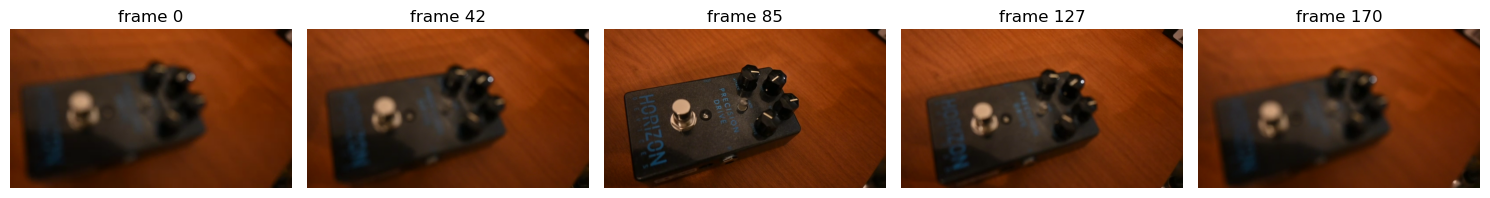

In [6]:
plot_frames(frames, N_FRAMES)

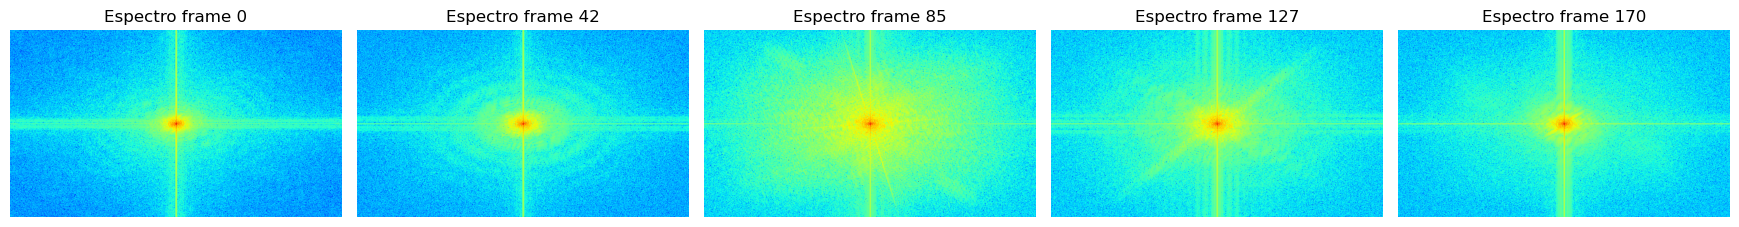

Frame   0 | Mínimo:   -2.56 dB | Máximo:  141.60 dB
Frame  42 | Mínimo:   -1.19 dB | Máximo:  142.01 dB
Frame  85 | Mínimo:   -6.35 dB | Máximo:  142.41 dB
Frame 127 | Mínimo:   -6.82 dB | Máximo:  142.77 dB
Frame 170 | Mínimo:   -7.53 dB | Máximo:  142.23 dB


In [ ]:
plot_espectros(frames, N_FRAMES)


La FFT descompone cada frame en ondas de distinta frecuencia: el centro del espectro es la frecuencia cero y, cuanto más alajado del centro, más rápido es el cambio de brillo que representa. Los bordes son cambios abruptos y requieren altas frecuencias, por lo que una imagen nítida tiene energía lejos del centro. Desenfocar equivale a promediar cada píxel con sus vecinos, lo que elimina los cambios rápidos (filtro pasa-bajos). Esto se observa en los plots: en los frames 0 y 170 el pedal está desenfocado y la mayor parte de la energía queda concentrada en el centro, mientras que en el frame 85, el más nítido, el espectro se expande hacia la periferia.

La métrica del paper cuantifica esa extensión: cuenta qué proporción de las frecuencias supera un umbral relativo al máximo, y a mayor proporción, mayor nitidez. Esperaríamos entonces encontrar un máximo cerca del frame 85 y mínimos en los extremos.

### Algoritmo que calcula métrica de Nitidez en Frecuencia (Paper)

El paper ["Image Sharpness Measure for Blurred Images in Frequency Domain" (De y Masilamani, 2013)](./data/tp2/ImageSharpnessMeasureforBlurredImagesinFrequency.pdf) propone una medida de nitidez sin referencia, llamada **FM** (*Frequency Domain Image Blur Measure*), basada en el espectro de Fourier. Su observación central es que, al aumentar el desenfoque, disminuye la cantidad de componentes de alta frecuencia.

Dada una imagen $I$ de tamaño $M \times N$, el paper propone el siguiente algoritmo:

1. Calcular la transformada de Fourier $F$ de la imagen $I$.
2. Hallar $F_c$, que se obtiene desplazando el origen de $F$ al centro.
3. Calcular la magnitud: $AF = \text{abs}(F_c)$, donde $AF$ es el valor absoluto de la transformada de Fourier centrada $F_c$ de la imagen $I$.
4. Calcular $AF_{\max} = \max(AF)$, donde $AF_{\max}$ es el valor máximo de las componentes de frecuencia de $F$. (Aclaración: es el valor que el paper denota $M$; lo renombramos para no confundirlo con el tamaño $M \times N$ de la imagen.)
5. Definir el umbral $\text{thres} = \dfrac{AF_{\max}}{1000}$ y contar los píxeles del espectro que lo superan:

$$T_H = \#\{(u,v) \;:\; AF(u,v) > \text{thres}\}$$

6. Calcular la medida de calidad de imagen (FM):

$$\text{Medida de calidad de imagen (FM)} = \frac{T_H}{M \times N} \tag{1}$$

Un valor de $FM$ mayor indica una imagen más nítida, ya que una mayor fracción de las frecuencias supera el umbral. El umbral $1/1000$ se fijó experimentalmente sobre el Berkeley Segmentation Dataset. Los autores muestran que $FM$ decrece de forma monótona al aumentar el desenfoque gaussiano o de movimiento.

In [8]:
def FM(img_rgb: np.ndarray, ratio: float = 1000) -> float:
    """Métrica FM del paper sobre una imagen o región RGB."""

    af: np.ndarray = calcular_espectro(img_rgb)        # pasos 1-3: FFT, centrado y |Fc| --> ya estaba implementado en los helpers
    af_max: float = af.max()                      # paso 4
    thres: float = af_max / ratio                 # umbral = AF_max / 1000
    t_h: int = np.count_nonzero(af > thres)     # paso 5: píxeles que superan el umbral
    m, n = af.shape
    return t_h / (m * n)                   # paso 6: FM = T_H / (M x N)

### Experimento 1: curva sobre el frame completo

Lo corremos sobre todos los frames y graficamos el resultado.

In [9]:
fm_completo: list[float] = [FM(f) for f in frames]

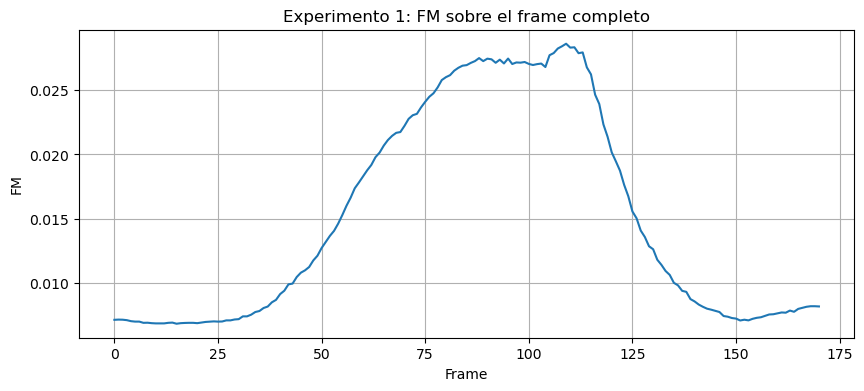

In [10]:
plot_processed_frames(fm_completo, ylabel='FM', xlabel='Frame', title='Experimento 1: FM sobre el frame completo')

### Experimento 2: ROI central

Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = 5 o 10% del area total del frame.

In [11]:
def get_roi_coordinates(frames: List[MatLike], area: float = 0.05, ) -> tuple[int, int, int, int]:
    """Definimos el area de interes (ROI) centrada en el frame"""

    # Todos los frames del video tienen la misma dimension
    H, W = frames[0].shape[:2]

    print(f"La dimension del video es: {W}x{H}")

    # Mantenemos la relación de aspecto del frame: escalar cada lado por sqrt(area)
    # hace que w*h = area * W*H
    escala = np.sqrt(area)
    w, h = int(round(W * escala)), int(round(H * escala))

    print(f"Area real = {w*h/(W*H):.2%}")

    # Esquina superior izquierda para que la ROI quede centrada
    x, y = (W - w) // 2, (H - h) // 2

    print(f"ROI: {w}x{h} en (x={x}, y={y})")
    return x, y, w, h 

Corremos sobre los frames del ROI de area 5% y graficamos el resultado.

La dimension del video es: 640x360
Area real = 4.97%
ROI: 143x80 en (x=248, y=140)


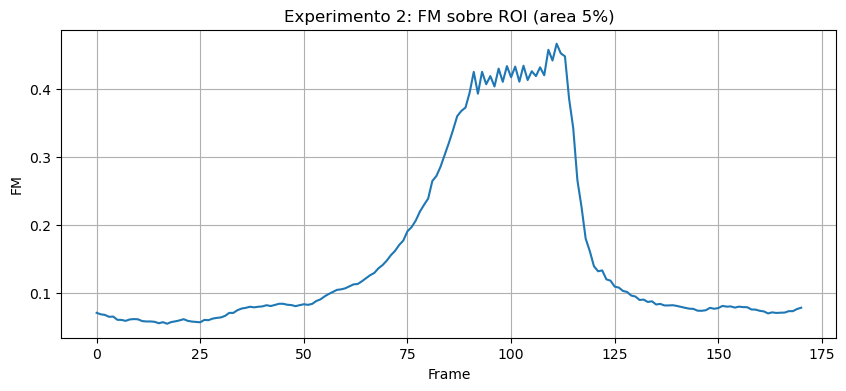

In [12]:
x, y, w, h = get_roi_coordinates(frames, area=0.05)

fm_over_roi_5_perc: list[np.float64] = [FM(f[y:y+h, x:x+w]) for f in frames]

plot_processed_frames(fm_over_roi_5_perc, 
                      ylabel='FM', 
                      xlabel='Frame', 
                      title='Experimento 2: FM sobre ROI (area 5%)'
                    )

Corremos sobre los frames del ROI de area 10% y graficamos el resultado.

La dimension del video es: 640x360
Area real = 9.99%
ROI: 202x114 en (x=219, y=123)


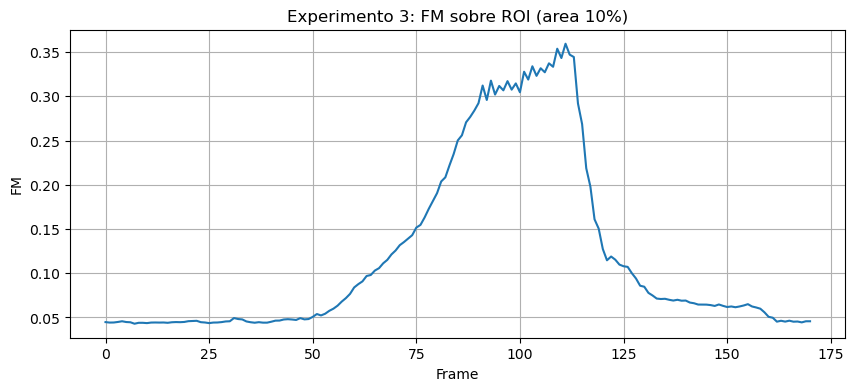

In [13]:
x, y, w, h = get_roi_coordinates(frames, area=0.10)

fm_over_roi_10_perc: list[np.float64] = [FM(f[y:y+h, x:x+w]) for f in frames]

plot_processed_frames(fm_over_roi_10_perc, 
                      ylabel='FM', 
                      xlabel='Frame', 
                      title='Experimento 3: FM sobre ROI (area 10%)'
                    )

### Detección automática del máximo y de la región de enfoque

Se identifica el máximo global de la métrica FM y la región
continua que contiene dicho máximo mediante un umbral
configurable del 95 %.

In [14]:
def detectar_maximo_enfoque(valores_fm: List[float]) -> Tuple[int, float]:
    """Detecta el frame de máximo enfoque y su valor FM."""

    frame_max = int(np.argmax(valores_fm))
    fm_max = float(valores_fm[frame_max])

    return frame_max, fm_max

max_completo, fm_max_completo = detectar_maximo_enfoque(fm_completo)

max_roi_5, fm_max_roi_5 = detectar_maximo_enfoque(fm_over_roi_5_perc)

max_roi_10, fm_max_roi_10 = detectar_maximo_enfoque(fm_over_roi_10_perc)


print("Detección automática del máximo enfoque")
print("-" * 60)

print(f"Frame completo | Frame: {max_completo} | FM: {fm_max_completo:.6f}")
print(f"ROI 5%         | Frame: {max_roi_5} | FM: {fm_max_roi_5:.6f}")
print(f"ROI 10%        | Frame: {max_roi_10} | FM: {fm_max_roi_10:.6f}")

Detección automática del máximo enfoque
------------------------------------------------------------
Frame completo | Frame: 109 | FM: 0.028624
ROI 5%         | Frame: 111 | FM: 0.465909
ROI 10%        | Frame: 111 | FM: 0.359389


In [16]:
def detectar_region_enfoque(
    valores_fm: List[float],
    porcentaje: float = 0.95
) -> Tuple[int, int]:

    """Detecta la región continua de máximo enfoque."""

    frame_max, fm_max = detectar_maximo_enfoque(valores_fm)

    umbral = porcentaje * fm_max

    inicio = frame_max
    fin = frame_max

    # Buscar hacia la izquierda
    while inicio > 0 and valores_fm[inicio - 1] >= umbral:
        inicio -= 1

    # Buscar hacia la derecha
    while fin < len(valores_fm) - 1 and valores_fm[fin + 1] >= umbral:
        fin += 1

    return inicio, fin

In [17]:
region_completo = detectar_region_enfoque(fm_completo)

region_roi_5 = detectar_region_enfoque(fm_over_roi_5_perc)

region_roi_10 = detectar_region_enfoque(fm_over_roi_10_perc)

print("Regiones de máximo enfoque (95%)")
print("-" * 60)

print("Frame completo:", region_completo)
print("ROI 5%:        ", region_roi_5)
print("ROI 10%:       ", region_roi_10)

Regiones de máximo enfoque (95%)
------------------------------------------------------------
Frame completo: (105, 113)
ROI 5%:         (111, 113)
ROI 10%:        (109, 113)


In [18]:
def plot_region_enfoque(
    valores_fm: List[float],
    title: str,
    porcentaje: float = 0.95
) -> None:

    frame_max, fm_max = detectar_maximo_enfoque(valores_fm)

    inicio, fin = detectar_region_enfoque(valores_fm, porcentaje)

    umbral = porcentaje * fm_max

    plt.figure(figsize=(10, 4))

    plt.plot(valores_fm, label="FM")

    # Máximo global
    plt.scatter(
        frame_max, fm_max,
        color="red",
        s=80,
        zorder=5,
        label=f"Máximo: frame {frame_max}"
    )

    # Umbral de enfoque
    plt.axhline(
        umbral,
        color="green",
        linestyle="--",
        label=f"Umbral: {porcentaje:.0%}"
    )

    # Región de máximo enfoque
    plt.axvspan(
        inicio, fin,
        color="green",
        alpha=0.20,
        label=f"Región: {inicio}-{fin}"
    )

    plt.xlabel("Frame")
    plt.ylabel("FM")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

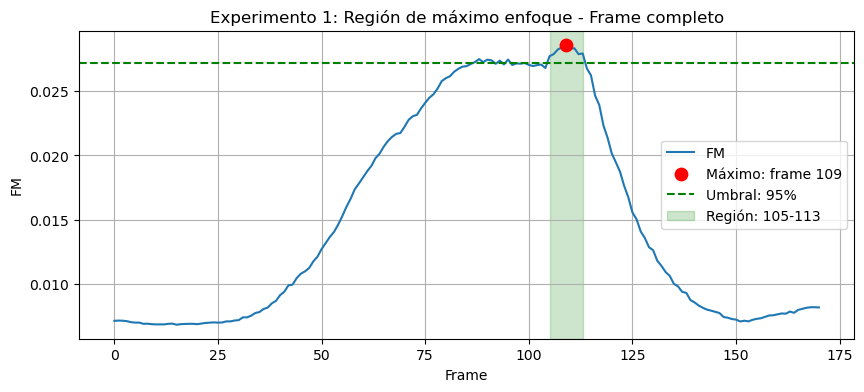

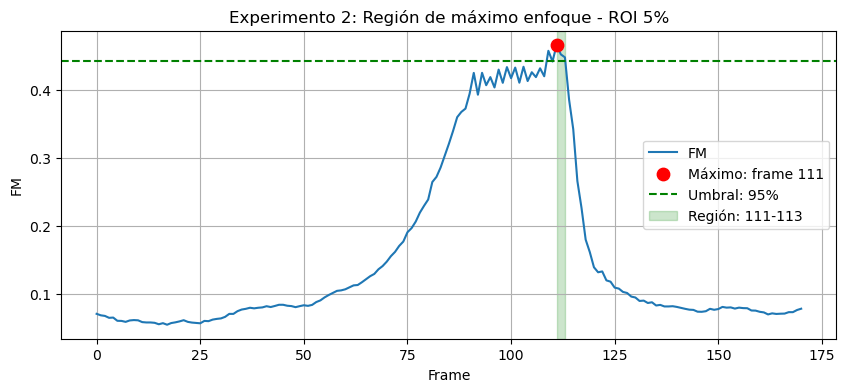

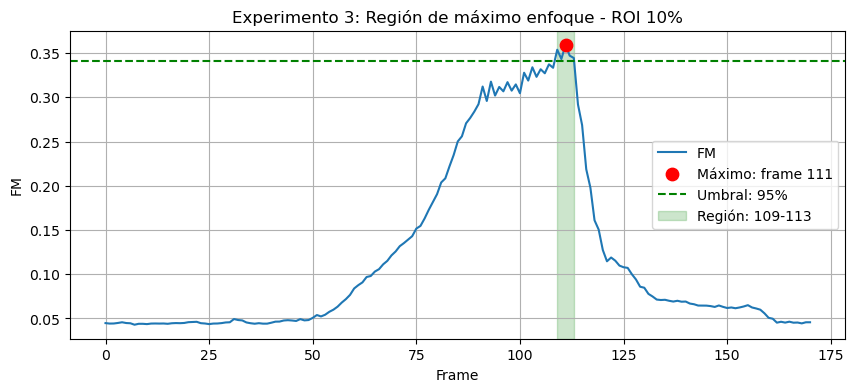

In [19]:
plot_region_enfoque(
    fm_completo,
    "Experimento 1: Región de máximo enfoque - Frame completo"
)

plot_region_enfoque(
    fm_over_roi_5_perc,
    "Experimento 2: Región de máximo enfoque - ROI 5%"
)

plot_region_enfoque(
    fm_over_roi_10_perc,
    "Experimento 3: Región de máximo enfoque - ROI 10%"
)

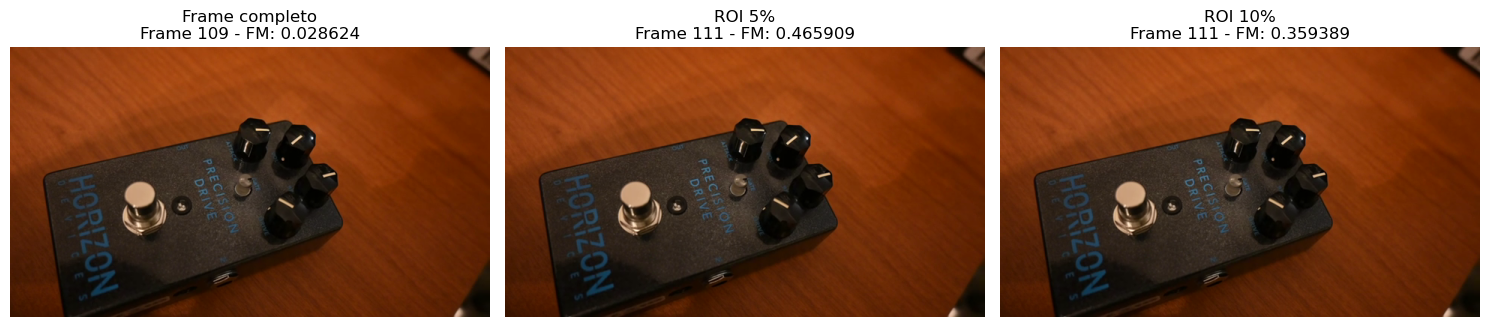

In [20]:
resultados = [
    ("Frame completo", max_completo, fm_max_completo),
    ("ROI 5%", max_roi_5, fm_max_roi_5),
    ("ROI 10%", max_roi_10, fm_max_roi_10)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (nombre, indice, valor_fm) in zip(axes, resultados):

    ax.imshow(frames[indice])
    ax.set_title(
        f"{nombre}\nFrame {indice} - FM: {valor_fm:.6f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Conclusiones

La métrica FM permitió detectar automáticamente el máximo enfoque en los tres experimentos realizados.

| Experimento | Frame máximo | FM máximo | Región de enfoque al 95 % |
|---|---:|---:|---:|
| Frame completo | 109 | 0.028624 | 105–113 |
| ROI 5 % | 111 | 0.465909 | 111–113 |
| ROI 10 % | 111 | 0.359389 | 109–113 |

Los tres experimentos presentan una elevada concordancia en la detección del máximo enfoque.

El frame completo presenta una curva más estable, mientras que las ROI permiten reducir el costo computacional y aumentar la sensibilidad relativa al enfoque, aunque presentan mayores oscilaciones.

La ROI del 10 % representa, para el video analizado, un buen compromiso entre estabilidad, sensibilidad y costo computacional.

Adicionalmente, se implementó la detección automática de la región continua de máximo enfoque mediante un umbral configurable del 95 %, sin aplicar suavizado ni modificar la métrica propuesta en el paper.

# Puntos extra: Unsharp Masking

Aplicar unsharp masking para expandir la zona de enfoque y devolver.


## Unsharp masking

- Es un algoritmo que tiene enfocar o mejorar los bordes con un filtro de suavizado
    1. Desenfoque de la imagen con un filtro suavizador (ej. Gaussiano)
        
        $$
        f(x,y) \rightarrow f_B(x,y)
        $$
        
    2. Resta de la imagen original con la suavizada (sobreviven componentes de alta frecuencia)
        
        $$
        m(x,y) = f(x,y) - f_B(x,y)
        $$
        
    3. Agregar esa máscara a la imagen original (realce de las componentes de alta frecuencia)
        
        $$
        g(x,y) = f(x,y) + k \cdot m(x,y)
        $$
        

De manera genérica:

$$
\mathbf{g(x,y) = (k+1) \cdot f(x,y) - k \cdot f_B(x,y)}
$$

- $k = 1$: Máscara de desenfoque (unsharp masking)
- $k > 1$: Filtrado de alto impulso (highboost filtering)

### Implementación con OpenCV

La fórmula genérica $g = (k+1) \cdot f - k \cdot f_B$ se traduce directamente a dos métodos de OpenCV:

1. `cv2.GaussianBlur(f, (0, 0), sigma)` → $f_B$. Con `ksize=(0, 0)` OpenCV calcula el tamaño del kernel a partir de `sigma`.
2. `cv2.addWeighted(f, k+1, f_B, -k, 0)` → $g$. Calcula la combinación lineal y **satura** el resultado a $[0, 255]$ en `uint8`, así que no hace falta hacer `np.clip` ni cambiar de tipo.

`sigma` controla qué tan "altas" son las frecuencias que se realzan (un sigma chico solo realza detalles finos) y `k` cuánto se amplifican.

In [21]:
def unsharp_masking(img: np.ndarray, k: float = 1.0, sigma: float = 2.0) -> np.ndarray:
    """Unsharp masking: g = (k+1)*f - k*f_B, con f_B = f suavizada con un filtro gaussiano.

    k = 1  -> unsharp masking clásico
    k > 1  -> highboost filtering
    """
    f_b = cv2.GaussianBlur(img, (0, 0), sigma)       # paso 1: f_B (pasa-bajos)
    return cv2.addWeighted(img, k + 1, f_b, -k, 0)   # pasos 2 y 3: f + k*(f - f_B), saturado a [0, 255]

### Efecto visual sobre un frame

Tomamos un frame de la transición (todavía algo desenfocado) y comparamos el original con su versión realzada para dos valores de $k$.

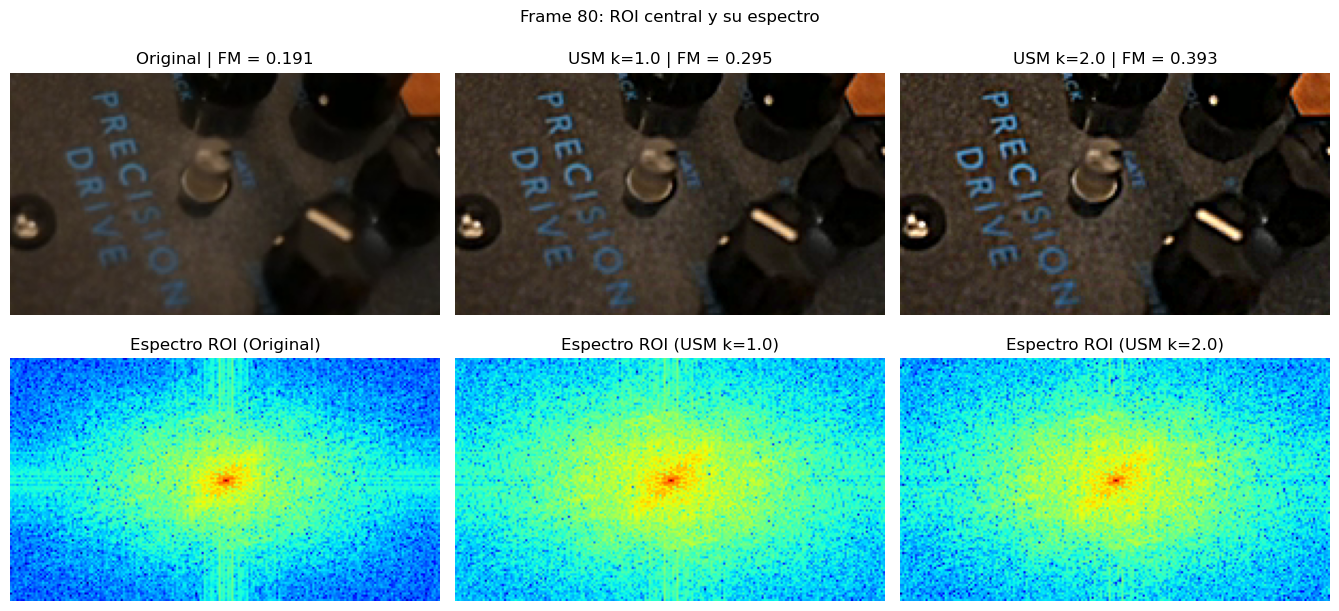

In [22]:
SIGMA = 2.0
KS = [1.0, 2.0]   # k = 1 (unsharp masking) y k = 2 (highboost)
FRAME_EJEMPLO = 80

original = frames[FRAME_EJEMPLO]
versiones = [("Original", original)] + [(f"USM k={k}", unsharp_masking(original, k, SIGMA)) for k in KS]

fig, axes = plt.subplots(2, len(versiones), figsize=(4.5 * len(versiones), 6.5))

for col, (titulo, img) in enumerate(versiones):
    roi_img = img[y:y+h, x:x+w]
    axes[0, col].imshow(roi_img)
    axes[0, col].set_title(f"{titulo} | FM = {FM(roi_img):.3f}")
    axes[0, col].axis('off')

    axes[1, col].imshow(20 * np.log10(calcular_espectro(roi_img) + 1e-5), cmap='jet')
    axes[1, col].set_title(f"Espectro ROI ({titulo})")
    axes[1, col].axis('off')

fig.suptitle(f"Frame {FRAME_EJEMPLO}: ROI central y su espectro")
plt.tight_layout()
plt.show()

### Expansión de la zona de enfoque

Aplicamos unsharp masking a todos los frames y repetimos la medición de FM sobre la misma ROI central del Experimento 2. El filtro se aplica al frame completo y después se recorta la ROI, para que el borde del recorte no introduzca artefactos del suavizado.

Para comparar las zonas de enfoque usamos un **umbral fijo**, definido sobre la curva original: un frame se considera "en foco" si su FM supera el 50% del FM máximo del video sin procesar. Usar el mismo umbral para todas las curvas permite ver cuántos frames adicionales pasan a estar en foco gracias al realce.

In [23]:
x, y, w, h = get_roi_coordinates(frames, area=0.05)
fm_over_roi: list[np.float64] = [FM(f[y:y+h, x:x+w]) for f in frames]

La dimension del video es: 640x360
Area real = 4.97%
ROI: 143x80 en (x=248, y=140)


In [24]:
def zona_de_enfoque(fm: List[float], umbral: float) -> np.ndarray:
    """Índices de los frames cuyo FM supera el umbral."""
    return np.flatnonzero(np.asarray(fm) >= umbral)

UMBRAL_ENFOQUE = 0.5 * max(fm_over_roi)

# FM sobre la ROI para cada k (el filtro se aplica al frame completo y luego se recorta)
curvas = {"Original": fm_over_roi}
for k in KS:
    curvas[f"USM k={k}"] = [FM(unsharp_masking(f, k, SIGMA)[y:y+h, x:x+w]) for f in frames]

print(f"Umbral de enfoque (fijo) = {UMBRAL_ENFOQUE:.3f}\n")
zonas = {}
for nombre, fm in curvas.items():
    zonas[nombre] = zona_de_enfoque(fm, UMBRAL_ENFOQUE)
    z = zonas[nombre]
    print(f"{nombre:>10}: máximo en frame {int(np.argmax(fm)):3d} | "
          f"{len(z):3d} frames en foco (frames {z.min()} a {z.max()})")

Umbral de enfoque (fijo) = 0.233

  Original: máximo en frame 111 |  37 frames en foco (frames 80 a 116)
 USM k=1.0: máximo en frame 111 |  47 frames en foco (frames 73 a 119)
 USM k=2.0: máximo en frame 111 |  56 frames en foco (frames 66 a 122)


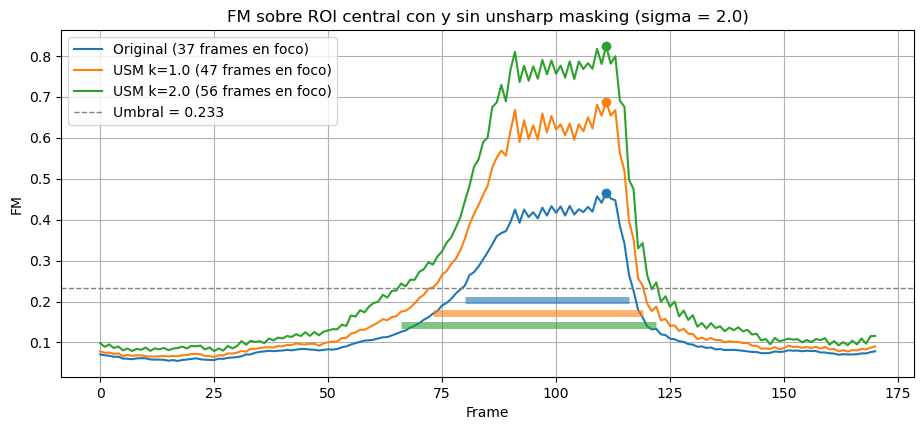

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.5))

for i, (nombre, fm) in enumerate(curvas.items()):
    linea, = ax.plot(fm, label=f"{nombre} ({len(zonas[nombre])} frames en foco)")
    z = zonas[nombre]
    # Banda de la zona de enfoque (escalonada debajo del umbral para que no se superpongan)
    ax.hlines(UMBRAL_ENFOQUE - 0.03 * (i + 1), z.min(), z.max(),
              colors=linea.get_color(), linewidth=5, alpha=0.6)
    ax.plot(np.argmax(fm), max(fm), 'o', color=linea.get_color())

ax.axhline(UMBRAL_ENFOQUE, color='gray', linestyle='--', linewidth=1, label=f"Umbral = {UMBRAL_ENFOQUE:.3f}")
ax.set_xlabel('Frame')
ax.set_ylabel('FM')
ax.set_title(f'FM sobre ROI central con y sin unsharp masking (sigma = {SIGMA})')
ax.legend(loc='upper left')
ax.grid(True)
plt.show()

### Conclusión

El unsharp masking amplifica las componentes de alta frecuencia ($f - f_B$), así que más coeficientes del espectro superan el umbral $AF_{\max}/1000$ y el FM sube en todos los frames. El efecto es mayor en los frames de transición, que todavía conservan bordes para realzar. En los frames muy desenfocados casi no queda alta frecuencia que amplificar.

Con el mismo umbral de enfoque, la zona de enfoque se expande:

| Curva | Frames en foco | Rango |
|---|---|---|
| Original | 37 | 80 – 116 |
| USM $k=1$ | 47 | 73 – 119 |
| USM $k=2$ | 56 | 66 – 122 |

El frame de máximo enfoque no cambia (frame 111): el realce ensancha la zona de enfoque, pero no altera cuál es el frame más nítido. Hay una contrapartida: el filtro también amplifica el ruido. Con $k$ grande (por ejemplo, $k = 4$) el FM de los frames desenfocados también sube, y el contraste entre frames enfocados y desenfocados se reduce.